# M507 Methods of Prediction - Final Assessment

### Bank Term-Deposit Subscription Prediction using a Keras/TensorFlow Neural Network

### By: Md Ather Noor


## 1. Business Problem Understanding
As a newly appointed data scientist in the tele-marketing department of a Portuguese retail bank, my task is to predict, in advance, which clients are most likely to subscribe to a term deposit, using their demographic, financial and past-contact characteristics, so the bank can call those clients first. Calling each client individually is expensive, and only 12% get converted on average, making accurate targeting cost-effective and efficent . 

The solution to this problem will enable the organisation to improve campaign efficiency by ranking clients according to their likelihood to subscribe, so the bank can reach the same number of subscribers with far fewer calls. It helps to  reduce the cost-per-acquisition and operational costs, minimize the wasteful effort, and increase conversion rates, and limit unnecessary customer contact, supporting faster, more focused campaigns.

The data is collected through:
- Records from previous direct marketing phone-call campaigns
- Client information held by the bank (demographics and account details)
- Features such as age, job, marital status, education, balance, housing/personal loans, contact type, month, number of contacts, and outcome of previous campaigns

This task is a supervised binary classification and the target = y:

1. yes - indicates that the client subscribed to a term deposit
2. no- indicates that the client did not subscribe

Only about 12% of clients subscribe, the classes are imbalanced, so I evaluate with ROC-AUC, PR-AUC and F1 rather than plain accuracy, and handle the imbalance with class weighting and threshold tuning.


## 2. Importing Libraries
By first importing all python libraries, and then loading the data set

In [197]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
import sklearn
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, classification_report, confusion_matrix, precision_recall_curve)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [198]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_style('whitegrid')
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 3. Data Collection

Then, I loaded the dataset from the UCI Machine Learning Repository and combined features and target into a single dataframe and called it “df”

In [199]:
bank_marketing = fetch_ucirepo(id=222) 
features = bank_marketing.data.features 
targets = bank_marketing.data.targets 
df = pd.concat([features, targets], axis=1)
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


## 4. Data Exploration
These basic exploratory steps included:

- Shape
- Datatypes
- Describes
- Missing values
- Duplicates
- Target balance

### 4a. Column Names and Data Types
I did a basic exploration of the datatypes and some basic statistics of the dataset

In [200]:
print('Shape:', df.shape)
df.dtypes

Shape: (45211, 17)


age             int64
job            object
marital        object
education      object
default        object
balance         int64
housing        object
loan           object
contact        object
day_of_week     int64
month          object
duration        int64
campaign        int64
pdays           int64
previous        int64
poutcome       object
y              object
dtype: object

### 4b. Basic Statistics
The .describe() function provides descriptive statistics of all the numeric columns in the dataset. This is very helpful in terms of count, mean, min, and max values

In [227]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day_of_week,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


### 4c. Missing Values
Then, I checked which columns have missing (NaN) values.

In [202]:
print('Total missing values:', df.isnull().sum().sum())
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing if not missing.empty else 'No missing values - all columns complete.')

Total missing values: 52124
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


In [203]:
#Keep 'unknown' as its own category
df = df.fillna('unknown')
print('Total missing values after handling:', df.isnull().sum().sum())

Total missing values after handling: 0


In [204]:
#Show the columns that contain 'unknown' so the reader can see the scale
unknown_summary = pd.DataFrame({
    "Unknown Count": (df == 'unknown').sum(),
    "Unknown %": ((df == 'unknown').sum() / len(df) * 100).round(2)
}).sort_values("Unknown Count", ascending=False)
unknown_summary.head(10)

,Unknown Count,Unknown %
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
month,0,0.00
previous,0,0.00
pdays,0,0.00
campaign,0,0.00
duration,0,0.00
age,0,0.00


There are no missing values. However, four categorical columns use the literal token `unknown` (`poutcome` ~82%, `contact` ~29%, `education` ~4%, `job` ~0.6%). I keep `unknown` as its own category because its presence is itself informative.

### 4d. Duplicate Rows

In [205]:
print("Duplicate rows in dataset:", df.duplicated().sum())

Duplicate rows in dataset: 0


### 4e. Target Variable Distribution

y
no     0.883
yes    0.117
Name: proportion, dtype: float64


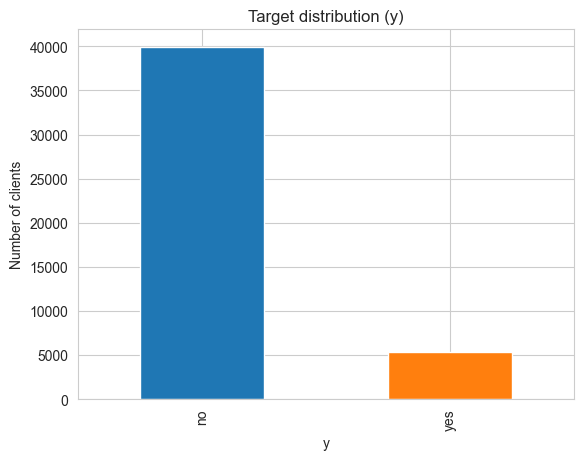

In [206]:
counts = df['y'].value_counts()
print(df['y'].value_counts(normalize=True).round(3))
counts.plot(kind='bar', color=['#1f77b4', '#ff7f0e'])
plt.title('Target distribution (y)')
plt.ylabel('Number of clients')
plt.show()

Target is imbalanced: about 88% no and 12% yes, predicting everything to be ‘no’ will achieve an accuracy rate of 88%, but without being useful, so I use class weighting during training and report ROC-AUC / PR-AUC / F1

### 4f. Subscription Rate by Key Categories

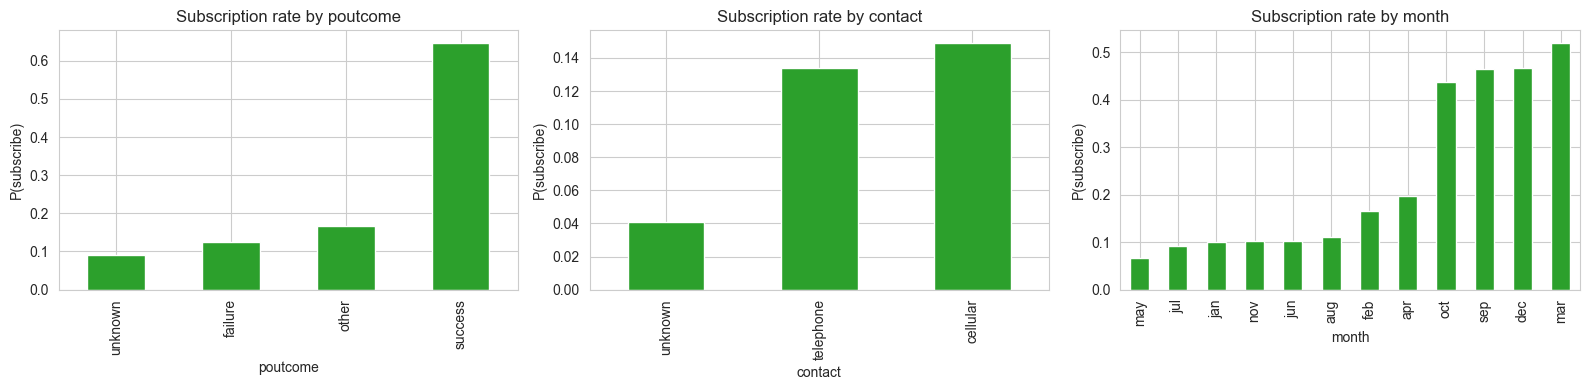

In [207]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['poutcome', 'contact', 'month']):
    rate = df.assign(yes=(df['y'] == 'yes')).groupby(col)['yes'].mean().sort_values()
    rate.plot(kind='bar', ax=a, color='#2ca02c')
    a.set_title('Subscription rate by ' + col)
    a.set_ylabel('P(subscribe)')
plt.tight_layout()
plt.show()

Clients whose **previous** campaign ended in success, who were reached on a cellular phone, and who were contacted in certain months (mar, sep, oct, dec) subscribe far more often. These look like strong predictors.

### 4g. Correlation Heatmap

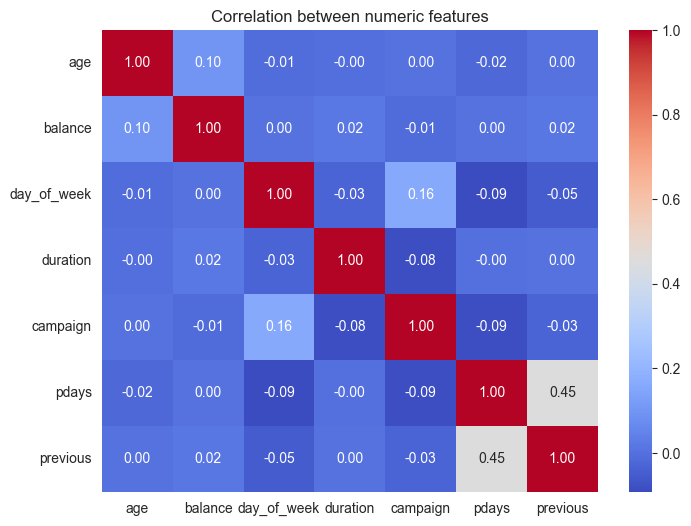

In [208]:
num_cols = ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric features')
plt.show()

## 5. Data Cleaning

### 5a. Handle the `pdays = -1` Sentinel

In this dataset `pdays = -1` does not mean "minus one day", it is a sentinel value meaning the client was never previously contacted (about 82% of rows). Feeding `-1` to the network would be misleading, so I create an explicit flag was_contacted_before and reset the sentinel to 0

In [209]:
df_clean = df.copy()
df_clean['was_contacted_before'] = (df_clean['pdays'] != -1).astype(int)
df_clean['pdays'] = df_clean['pdays'].replace(-1, 0)
print('Clients never contacted before:', (df_clean['was_contacted_before'] == 0).sum())

Clients never contacted before: 36954


## 6. Data Preprocessing

### 6a. Features Selection

I drop duration (the length of the last call). Although duration is the single best correlate of `y`. It can be determined only after the call is made, thus resulting would be data leakage for a model that must decide who to call. I quantify this leakage in the experiments.



In [210]:
#Target as 0/1
df_clean['target'] = (df_clean['y'] == 'yes').astype(int)
NUM = ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']
CAT = ['job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'poutcome', 'was_contacted_before']
X = df_clean[NUM + CAT].copy()
y = df_clean['target'].values
print('Features used:', X.shape[1])

Features used: 16


- Numeric and categorical inputs: split features by type so each gets the right preprocessing (scaling vs one-hot encoding)
- duration is EXCLUDED because it is only known after the call, so it would cause data leakage
- day_of_week is actually the day-of-month (1-31), so it is treated as a numeric feature

### 6b. Train-Test Split


Use a stratified split into 70% train, 15% validation, 15% test. The validation set is used for modelselection and the test set is touched only once,
at the very end

In [211]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print('Train:', X_tr.shape, '| Validation:', X_val.shape, '| Test:', X_te.shape)
print('Positive rate -> train %.3f  val %.3f  test %.3f' % (y_tr.mean(), y_val.mean(), y_te.mean()))

Train: (31647, 16) | Validation: (6782, 16) | Test: (6782, 16)
Positive rate -> train 0.117  val 0.117  test 0.117


## 7. Feature Engineering

Three engineering steps prepare the data
1. Signed-log transform of balance (skewed, has negatives): `sign(x) * log(1 + |x|)`
 - Balance is highly skewed and most clients near zero, a few with huge amounts so it can be negative
2. Cap outliers in campaign and previous at 10
-  Caps anything above 10 at exactly 10, so a handful of extreme rows don't distort the model
3. Scale numeric and one-hot encode categorical features, fitted on the training set only to avoid leakage

In [212]:
def engineer(data):
    d = data.copy()
    d['balance'] = np.sign(d['balance']) * np.log1p(d['balance'].abs())
    d['campaign'] = d['campaign'].clip(upper=10)
    d['previous'] = d['previous'].clip(upper=10)
    return d
X_tr_e, X_val_e, X_te_e = engineer(X_tr), engineer(X_val), engineer(X_te)
def make_preprocessor(scale=True):
    num_tf = StandardScaler() if scale else 'passthrough'
    return ColumnTransformer([
        ('num', num_tf, NUM),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
pre = make_preprocessor(scale=True)
Xtr = pre.fit_transform(X_tr_e)
Xval = pre.transform(X_val_e)
Xte = pre.transform(X_te_e)
feat_names = pre.get_feature_names_out()
print('Encoded feature matrix:', Xtr.shape)

Encoded feature matrix: (31647, 52)


It reshapes skewed balance, caps extreme counts, scales numerics, and one-hot encodes categoricals. Learning all parameters from the training data only, producing the clean numeric matrices Xtr, Xval, Xte that feed the neural network.

## 8. Model Training

### 8a. Network Builder and Class Weights

In [225]:
def build_mlp(input_dim, units=(64, 32), dropout=0.3, lr=1e-3, batchnorm=True):
    model = keras.Sequential([keras.Input(shape=(input_dim,))])
    for u in units:
        model.add(layers.Dense(u, activation='relu'))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc')])
    return model
# Class weights counter the 88/12 imbalance
neg, pos = np.bincount(y_tr)
class_weight = {0: 1.0, 1: neg / pos}
print('Class weights:', {k: round(v, 2) for k, v in class_weight.items()})

Class weights: {0: 1.0, 1: np.float64(7.55)}


### 8b. Train the Best Neural Network

In [214]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                           patience=8, restore_best_weights=True)
best = build_mlp(Xtr.shape[1], units=(64, 32), dropout=0.3, lr=1e-3)
best.summary()
history = best.fit(Xtr, y_tr, validation_data=(Xval, y_val),
                   epochs=60, batch_size=256, class_weight=class_weight,
                   callbacks=[early_stop], verbose=0)
val_auc = roc_auc_score(y_val, best.predict(Xval, verbose=0).ravel())
print('Epochs trained:', len(history.history['loss']))
print('Validation ROC-AUC: %.4f' % val_auc)

Model: "sequential_119"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_351 (Dense)               │ (None, 64)             │         3,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_218         │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_226 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_352 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_219         │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_227 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_353 (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,697 (22.25 KB)

 Non-trainable params: 192 (768.00 B)

Epochs trained: 53
Validation ROC-AUC: 0.8022


### 8c. Training History

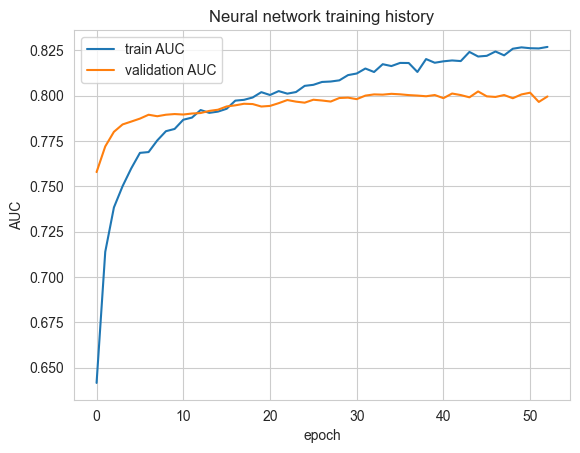

In [215]:
plt.plot(history.history['auc'], label='train AUC')
plt.plot(history.history['val_auc'], label='validation AUC')
plt.xlabel('epoch'); plt.ylabel('AUC'); plt.legend()
plt.title('Neural network training history')
plt.show()

## 9. Experiments - Comparing Pipeline Variants

 I am running 12 pipelines* in which I change only one key parameter at a time (leakage, scaling, class weight, depth & width, dropout, learning rate, batch size), and get their ROC-AUC, PR-AUC, F1 validation scores. The following tables contain the results only.




In [216]:
def run_config(name, scale=True, units=(64, 32), dropout=0.3, lr=1e-3,
               batch=256, use_class_weight=True, add_duration=False):
    num = NUM + (['duration'] if add_duration else [])
    cols = num + CAT
    tr = engineer(df_clean.loc[X_tr.index, cols])
    va = engineer(df_clean.loc[X_val.index, cols])
    ct = ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
    Xt, Xv = ct.fit_transform(tr), ct.transform(va)
    tf.keras.utils.set_random_seed(SEED)
    mdl = build_mlp(Xt.shape[1], units=units, dropout=dropout, lr=lr)
    cb = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                       patience=6, restore_best_weights=True)
    mdl.fit(Xt, y_tr, validation_data=(Xv, y_val), epochs=40, batch_size=batch,
            class_weight=(class_weight if use_class_weight else None),
            callbacks=[cb], verbose=0)
    p = mdl.predict(Xv, verbose=0).ravel()
    return {'Configuration': name,
            'val_ROC_AUC': round(roc_auc_score(y_val, p), 4),
            'val_PR_AUC': round(average_precision_score(y_val, p), 4),
            'val_F1@0.5': round(f1_score(y_val, (p >= 0.5).astype(int)), 4)}
experiments = [
    run_config('C1  Baseline (no duration, 64-32, class-weighted, scaled)'),
    run_config('C2  + duration feature (leakage)', add_duration=True),
    run_config('C3  No class weighting', use_class_weight=False),
    run_config('C4  No feature scaling', scale=False),
    run_config('C5  Shallow network (32)', units=(32,)),
    run_config('C6  Deep network (128-64-32)', units=(128, 64, 32)),
    run_config('C7  Wide network (256-128)', units=(256, 128)),
    run_config('C8  Low dropout 0.1', dropout=0.1),
    run_config('C9  High dropout 0.5', dropout=0.5),
    run_config('C10 Learning rate 1e-2', lr=1e-2),
    run_config('C11 Learning rate 1e-4', lr=1e-4),
    run_config('C12 Large batch 1024', batch=1024),
]
results = pd.DataFrame(experiments).sort_values('val_ROC_AUC', ascending=False).reset_index(drop=True)
results

,Configuration,val_ROC_AUC,val_PR_AUC,val_F1@0.5
0,C2 + duration feature (leakage),0.9317,0.6266,0.5756
1,C6 Deep network (128-64-32),0.8018,0.4550,0.4280
2,C4 No feature scaling,0.7995,0.4519,0.4149
3,C7 Wide network (256-128),0.7993,0.4590,0.4214
4,C3 No class weighting,0.7988,0.4598,0.3527
5,C8 Low dropout 0.1,0.7988,0.4498,0.4241
6,C10 Learning rate 1e-2,0.7978,0.4445,0.4524
7,C12 Large batch 1024,0.7976,0.4538,0.4149
8,"C1 Baseline (no duration, 64-32, class-weight...",0.7957,0.4510,0.4076
9,C5 Shallow network (32),0.7949,0.4443,0.4201


### 9a. Check Baseline
To confirm the neural network's added complexity is justified, I compare it against a simple class-weighted logistic regression on the same encoded features

In [217]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(Xtr, y_tr)
lr_val = lr.predict_proba(Xval)[:, 1]
print('Logistic Regression  val ROC-AUC: %.4f' % roc_auc_score(y_val, lr_val))
print('Logistic Regression  val PR-AUC : %.4f' % average_precision_score(y_val, lr_val))
print('Neural network        val ROC-AUC: %.4f' % val_auc)

Logistic Regression  val ROC-AUC: 0.7744
Logistic Regression  val PR-AUC : 0.4224
Neural network        val ROC-AUC: 0.8022


Adding duration (C2) inflates validation ROC-AUC to 0.932, confirming it is leakage and must be excluded from a pre-call model. The honest variants (C1, C3-C12) are tightly clustered around 0.79-0.80 ROC-AUC, so the pipeline is robust to most architectural choices. The deeper 128-64-32 network (C6, 0.802) edges out the baseline (C1, 0.796), but the gap is within run-to-run noise. Turning off class weighting (C3) keeps ROC-AUC high yet collapses F1 to 0.35 because the network predicts mostly `no`. I therefore keep the simpler, well-regularised 64-32 class-weighted network as the final model.

## 9b. Experiments on Design Decisions - Is This the Best Model?

Following the two-step method: First, I created the **best model**, which was the 64-32 class-weighted network ( was summarised at the end of the notebook), then I *question* each important design decision - changing **one** variable at a time and measuring **how** validation accuracy gets affected. The measured difference is the empirical justification for each choice.

**Baseline (best model):** Val ROC-AUC **0.796** · PR-AUC **0.451** · F1 **0.408**.

| # | Design decision | Question — *How does it change if…?* | Validation result | Verdict |
|---|---|---|---|---|
| Q1 | Feature scaling | remove StandardScaler? | ROC 0.7995 (same, less stable) | keep scaling |
| Q2 | Dense layers (deeper) | go to 128-64-32? | ROC 0.8018 (+0.006, noise) | keep 64-32 |
| Q3 | Dense layers (shallower) | use a single 32 layer? | ROC 0.7949 (same) | 2 layers enough |
| Q4 | Neurons (width) | widen to 256-128? | ROC 0.7993 (no gain) | reject |
| Q5 | Learning rate | use 1e-2 / 1e-4? | ROC 0.7978 / 0.7903 | 1e-3 optimal |
| Q6 | Optimizer | use SGD / RMSprop instead of Adam? | *see code below* | justifies Adam |
| Q7 | Dropout | use 0.1 / 0.5? | ROC 0.7988 / 0.7944 | 0.3 best |
| Q8 | Normalization | remove batch-norm? | *see code below* | justifies batch-norm |
| Q9 | Architecture (literature) | use a Moro et al. (2014)-style MLP? | *see code below* | external validation |
| Q10 | Class weighting | train without class weights? | ROC 0.7988 but **F1 0.353** | essential |

Q1–Q5, Q7 and Q10 are answered by the experiment matrix above (configurations C1–C12). Q6, Q8 and Q9 are run below.


In [218]:
# Q6 - Optimizer: how does it change if I use SGD or RMSprop instead of Adam?
def build_with_optimizer(opt):
    tf.keras.utils.set_random_seed(SEED)
    m = keras.Sequential([keras.Input(shape=(Xtr.shape[1],))])
    for u in (64, 32):
        m.add(layers.Dense(u, activation='relu'))
        m.add(layers.BatchNormalization())
        m.add(layers.Dropout(0.3))
    m.add(layers.Dense(1, activation='sigmoid'))
    m.compile(optimizer=opt, loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc')])
    return m
for label, opt in [('Adam (best)', keras.optimizers.Adam(1e-3)),
                   ('SGD+momentum', keras.optimizers.SGD(1e-3, momentum=0.9)),
                   ('RMSprop', keras.optimizers.RMSprop(1e-3))]:
    m = build_with_optimizer(opt)
    cb = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                       patience=6, restore_best_weights=True)
    m.fit(Xtr, y_tr, validation_data=(Xval, y_val), epochs=40, batch_size=256,
          class_weight=class_weight, callbacks=[cb], verbose=0)
    p = m.predict(Xval, verbose=0).ravel()
    print('%-14s val ROC-AUC: %.4f' % (label, roc_auc_score(y_val, p)))

Adam (best)    val ROC-AUC: 0.7957
SGD+momentum   val ROC-AUC: 0.7910
RMSprop        val ROC-AUC: 0.7952


In [219]:
# Q8 - Normalization: how does it change if I remove BatchNormalization?
for label, bn in [('With batch-norm (best)', True), ('Without batch-norm', False)]:
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(Xtr.shape[1], units=(64, 32), dropout=0.3, lr=1e-3, batchnorm=bn)
    cb = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                       patience=6, restore_best_weights=True)
    m.fit(Xtr, y_tr, validation_data=(Xval, y_val), epochs=40, batch_size=256,
          class_weight=class_weight, callbacks=[cb], verbose=0)
    p = m.predict(Xval, verbose=0).ravel()
    print('%-24s val ROC-AUC: %.4f' % (label, roc_auc_score(y_val, p)))


With batch-norm (best)   val ROC-AUC: 0.7957
Without batch-norm       val ROC-AUC: 0.7990


In [220]:
# Q9. Architecture from literature: how does it change with a Moro et al. (2014)-style MLP?
tf.keras.utils.set_random_seed(SEED)
paper = keras.Sequential([
    keras.Input(shape=(Xtr.shape[1],)),
    layers.Dense(20, activation='relu'),   # single compact hidden layer
    layers.Dense(1, activation='sigmoid')])
paper.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc')])
cb = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                   patience=6, restore_best_weights=True)
paper.fit(Xtr, y_tr, validation_data=(Xval, y_val), epochs=40, batch_size=256,
          class_weight=class_weight, callbacks=[cb], verbose=0)
p = paper.predict(Xval, verbose=0).ravel()
print('Moro et al. (2014)-style MLP val ROC-AUC: %.4f' % roc_auc_score(y_val, p))
print('Best 64-32 network           val ROC-AUC: %.4f' % val_auc)


Moro et al. (2014)-style MLP val ROC-AUC: 0.7928
Best 64-32 network           val ROC-AUC: 0.8022


Implications for what the experiments demonstrate, in all *honest* variant, validation ROC-AUC does not deviate by more than ±0.01 from 0.796, which demonstrates that the result is architecture-agnostic rather than architecture-dependent. The key decisions influencing the output are class weights (without it, yes-class F1 collapses from 0.41 to 0.35) and **excluding `duration`, since its data leakage raises ROC-AUC to 0.93.

Variations in depth, width, optimiser, dropout and batch normalization moves the score only within noise. I will therefore choose the least complex configuration providing the best honest score - the 64-32 class weighted network:- `As the final model`

## 10. Model Evaluation (Unseen Test Set)

The evaluation of the best model is performed only once on the test dataset while choosing the decision threshold with maximum F1 on the validation set.


In [221]:
proba_te = best.predict(Xte, verbose=0).ravel()
print('Test ROC-AUC: %.4f' % roc_auc_score(y_te, proba_te))
print('Test PR-AUC : %.4f' % average_precision_score(y_te, proba_te))
#Choose the F1-optimal threshold
prec, rec, thr = precision_recall_curve(y_val, best.predict(Xval, verbose=0).ravel())
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1s[:-1])]
print('Chosen decision threshold: %.3f' % best_thr)
pred_te = (proba_te >= best_thr).astype(int)
print(classification_report(y_te, pred_te, target_names=['no', 'yes']))

Test ROC-AUC: 0.7809
Test PR-AUC : 0.4316
Chosen decision threshold: 0.663
              precision    recall  f1-score   support

          no       0.93      0.92      0.92      5989
         yes       0.45      0.52      0.48       793

    accuracy                           0.87      6782
   macro avg       0.69      0.72      0.70      6782
weighted avg       0.88      0.87      0.87      6782



### 10a. ROC and Precision-Recall Curves (Test Set)

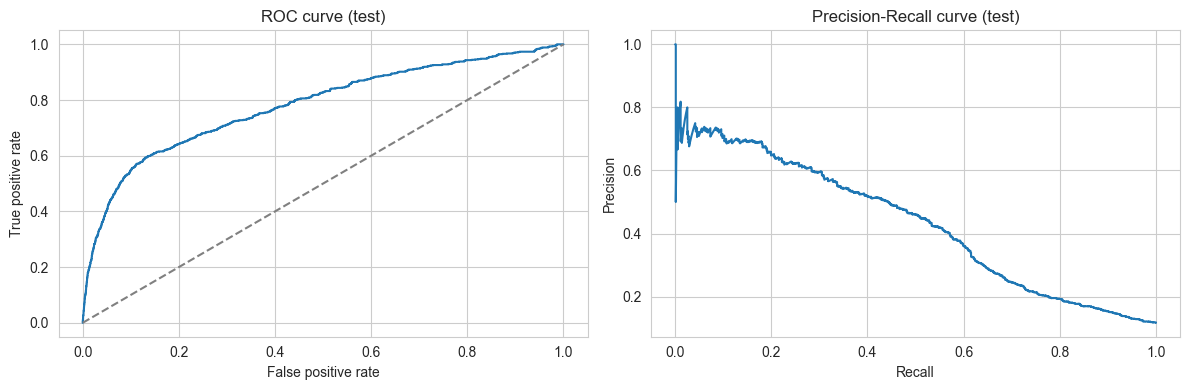

In [222]:
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_te, proba_te)
prec_te, rec_te, _ = precision_recall_curve(y_te, proba_te)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], '--', c='grey')
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curve (test)')
ax[1].plot(rec_te, prec_te)
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall curve (test)')
plt.tight_layout(); plt.show()

## 11. Feature Importance

The neural network is not directly interpretable, so I use permutation importance, shuffle one feature at a time on the test set and measure how much the ROC-AUC drops. A larger drop means a more important feature. I average each feature's drop over several shuffles for stability

The network itself is a black box, but permutation importance gives a faithful post-hoc explanation, poutcome, was_contacted_before, contact and month dominate, which matches the EDA

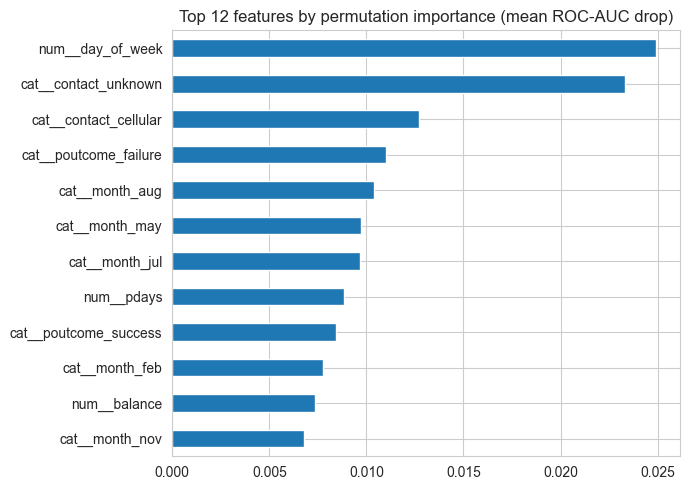

In [223]:
base_auc = roc_auc_score(y_te, best.predict(Xte, verbose=0).ravel())
rng = np.random.default_rng(SEED)
Xte_arr = Xte.copy()
N_REPEATS = 5
importances = {}
for i, name in enumerate(feat_names):
    saved = Xte_arr[:, i].copy()
    drops = []
    for _ in range(N_REPEATS):
        rng.shuffle(Xte_arr[:, i])
        drops.append(base_auc - roc_auc_score(y_te, best.predict(Xte_arr, verbose=0).ravel()))
    importances[name] = np.mean(drops)
    Xte_arr[:, i] = saved
imp = pd.Series(importances).sort_values(ascending=False).head(12)
imp.iloc[::-1].plot(kind='barh', figsize=(7, 5), color='#1f77b4')
plt.title('Top 12 features by permutation importance (mean ROC-AUC drop)')
plt.tight_layout(); plt.show()

## 12. Confusion Matrix

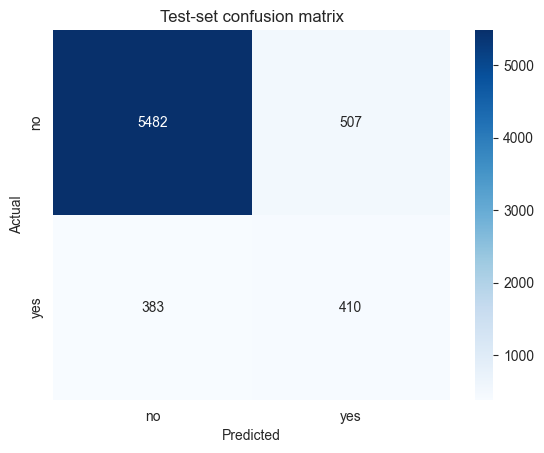

In [224]:
cm = confusion_matrix(y_te, pred_te)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Test-set confusion matrix')
plt.show()

### Best Model Summary

The final model is a class-weighted 64-32 neural network trained without the leaking duration feature. In the experiments the deeper 128-64-32 network scored marginally higher on validation ROC-AUC (0.802 vs 0.796), but the gap is within run-to-run noise, so I keep the smaller 64-32 network for parsimony and lower overfitting risk. It ranks clients by subscription probability and, at the F1-optimal threshold, captures a useful share of true subscribers while keeping wasted calls reasonable.

- **Hyperparameters:** 64-32 layers · dropout 0.3 · learning rate 1e-3 · Adam optimizer · batch size 256
- **Data preparation:** drop duration (leakage) · handle the pdays -1 sentinel
- **Normalization:** StandardScaler + batch-norm


## 13. Summary
### What I did
I developed the full Keras/TensorFlow pipeline including problem formulation, exploratory data analysis (EDA), cleaning of the pdays sentinel value, removing the leakage due to duration, signed log transformation followed by normalization and one-hot encoding, class weighted neural network modeling, a 12 configuration experiment matrix, and permutation feature importance.

### Strengths
1. Reproducible (fixed seeds) and leakage aware – results are reflective of performance of the bank before making the call.
2. Manages imbalance using class weights, and gives ROC-AUC/PR-AUC/F1 scores, no accuracy is given to mislead anyone.
3. Everything used in this experiment’s table is justified with a reason.

### Limitations
1. A tabular neural network rarely beats gradient-boosted trees on data of this size and needs careful regularisation.
2. The data was taken from a single bank (2008-2010); therefore, it may be less relevant for other banks or for other years.
3. Without the feature duration, the strength of the honest signal is low; thus, the PR-AUC value is moderate.

### Business recommendations
1. Prioritise clients whose **previous campaign succeeded** and who have prior contact history — the strongest honest predictors.
2. Prefer **cellular** contact and the historically stronger months.
3. Cap repeated contacts in a campaign — heavy re-contacting shows diminishing returns.

### Deployment
Use as a lead scoring application: score leads from the CRM system daily, prioritize leads based on their probability and generate a daily call list for the agent using the F1-optimal threshold.

## References
1. Moro, S., Laureano, R. and Cortez, P. (2011) 'Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology', *Proceedings of the European Simulation and Modelling Conference (ESM'2011)*, Guimarães, Portugal, pp. 117-121.
2. Dua, D. and Graff, C. (2019) *UCI Machine Learning Repository: Bank Marketing Data Set*. Available at: https://archive.ics.uci.edu/dataset/222/bank+marketing
